# Segmentación de clientes bancarios

Este notebook reproduce el análisis completo sobre el archivo `bank_transactions.csv` (1 048 567 transacciones). Para ejecutarlo, descarga el dataset según `data/README.md`.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

pd.set_option("display.float_format", lambda x: f"{x:,.1f}")

## 1. Carga y revisión inicial

In [6]:
df = pd.read_csv("../data/bank_transactions.csv")
print(df.shape)
df.info()
print(df.isnull().sum())

(1048567, 9)
<class 'pandas.DataFrame'>
RangeIndex: 1048567 entries, 0 to 1048566
Data columns (total 9 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   TransactionID            1048567 non-null  str    
 1   CustomerID               1048567 non-null  str    
 2   CustomerDOB              1045170 non-null  str    
 3   CustGender               1047467 non-null  str    
 4   CustLocation             1048416 non-null  str    
 5   CustAccountBalance       1046198 non-null  float64
 6   TransactionDate          1048567 non-null  str    
 7   TransactionTime          1048567 non-null  int64  
 8   TransactionAmount (INR)  1048567 non-null  float64
dtypes: float64(2), int64(1), str(6)
memory usage: 72.0 MB
TransactionID                 0
CustomerID                    0
CustomerDOB                3397
CustGender                 1100
CustLocation                151
CustAccountBalance         2369
TransactionDate    

## 2. Limpieza

- `CustomerDOB` usa `1/1/1800` como valor de relleno: se trata como dato faltante.
- Las fechas de dos dígitos de `%y` pueden caer en el futuro (por ejemplo, 2068); esas fechas se restan 100 años.
- Se calcula la edad a la fecha de la última transacción.

In [7]:
df["CustomerDOB"] = df["CustomerDOB"].replace("1/1/1800", pd.NA)
df["CustomerDOB"] = pd.to_datetime(df["CustomerDOB"], format="%d/%m/%y", errors="coerce")
df["CustomerDOB"] = df["CustomerDOB"].where(
    df["CustomerDOB"].dt.year <= 2016,
    df["CustomerDOB"] - pd.DateOffset(years=100)
)

df["TransactionDate"] = pd.to_datetime(df["TransactionDate"], format="%d/%m/%y", errors="coerce")
fecha_ref = df["TransactionDate"].max()
df["Edad"] = (fecha_ref - df["CustomerDOB"]).dt.days // 365.25

print("Fecha de referencia:", fecha_ref)
print("Nulos en CustomerDOB:", df["CustomerDOB"].isnull().sum())
print(df["Edad"].describe())
print("Menores de 18:", (df["Edad"] < 18).sum())

Fecha de referencia: 2016-10-21 00:00:00
Nulos en CustomerDOB: 60736
count   987,831.0
mean         30.9
std           8.8
min           0.0
25%          25.0
50%          29.0
75%          34.0
max          98.0
Name: Edad, dtype: float64
Menores de 18: 1816


## 3. Filtro y agregación por cliente

Se excluyen menores de 18 años y se construye una fila por cliente.

In [8]:
df = df[df["Edad"] >= 18]

clientes = df.groupby("CustomerID").agg(
    num_transacciones=("TransactionID", "count"),
    monto_total=("TransactionAmount (INR)", "sum"),
    monto_promedio=("TransactionAmount (INR)", "mean"),
    saldo_promedio=("CustAccountBalance", "mean"),
    edad=("Edad", "first"),
    genero=("CustGender", "first"),
    ubicacion=("CustLocation", "first"),
).reset_index()

print(clientes.shape)
clientes.head()

(839591, 8)


,CustomerID,num_transacciones,monto_total,monto_promedio,saldo_promedio,edad,genero,ubicacion
0,C1010011,2,"5,106.0","2,553.0","76,340.6",24.0,F,NOIDA
1,C1010012,1,"1,499.0","1,499.0","24,204.5",22.0,M,MUMBAI
2,C1010014,2,"1,455.0",727.5,"100,113.0",24.0,F,MUMBAI
3,C1010018,1,30.0,30.0,496.2,26.0,F,CHAMPARAN
4,C1010024,1,"5,000.0","5,000.0","87,058.6",51.0,M,KOLKATA


## 4. Transformación y escalado

Montos y saldos son muy asimétricos, así que se aplica logaritmo y luego estandarización. Se eliminan los clientes sin saldo.

In [9]:
X = clientes[["num_transacciones", "monto_total", "monto_promedio", "saldo_promedio", "edad"]].copy()
for col in ["monto_total", "monto_promedio", "saldo_promedio"]:
    X[col] = np.log1p(X[col])

X = X.dropna()
print("Clientes para clustering:", len(X))

scaler = StandardScaler()
X_escalado = scaler.fit_transform(X)

Clientes para clustering: 838055


## 5. Elección de k

Método del codo (con muestra de 50 000 clientes para que sea rápido) y coeficiente de silueta.

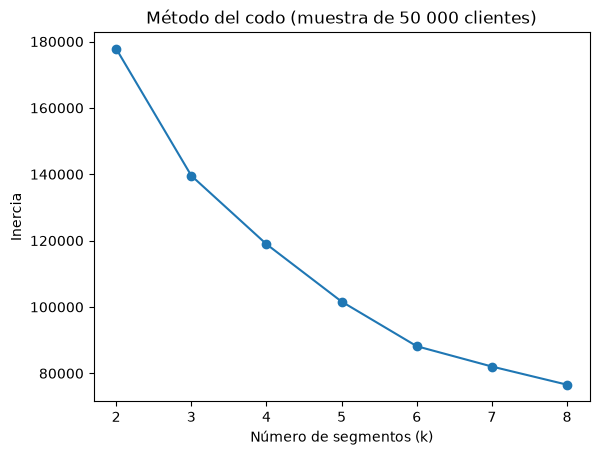

In [10]:
rng = np.random.RandomState(42)
X_muestra = X_escalado[rng.choice(len(X_escalado), 50000, replace=False)]

inercias = []
rango_k = range(2, 9)
for k in rango_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_muestra)
    inercias.append(km.inertia_)

plt.plot(list(rango_k), inercias, marker="o")
plt.xlabel("Número de segmentos (k)")
plt.ylabel("Inercia")
plt.title("Método del codo (muestra de 50 000 clientes)")
plt.show()

In [11]:
X_sil = X_muestra[:5000]
for k in [4, 5]:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = km.fit_predict(X_sil)
    print(f"k={k}  silueta={silhouette_score(X_sil, etiquetas):.3f}")

k=4  silueta=0.298
k=5  silueta=0.310


## 6. Modelo final (k=4)

Se entrena K-Means sobre todos los clientes y se describe cada segmento con medianas, porque los montos tienen valores extremos.

In [12]:
km_final = KMeans(n_clusters=4, random_state=42, n_init=10)
km_final.fit(X_escalado)

clientes_seg = clientes.loc[X.index].copy()
clientes_seg["segmento"] = km_final.labels_

perfil = clientes_seg.groupby("segmento").agg(
    clientes=("CustomerID", "count"),
    num_transacciones=("num_transacciones", "median"),
    monto_total=("monto_total", "median"),
    monto_promedio=("monto_promedio", "median"),
    saldo_promedio=("saldo_promedio", "median"),
    edad=("edad", "median"),
)
perfil["porcentaje"] = (perfil["clientes"] / perfil["clientes"].sum() * 100).round(1)

print(perfil.round(1))

          clientes  num_transacciones  monto_total  monto_promedio  \
segmento                                                             
0           334036                1.0        900.0           900.0   
1           285536                1.0        108.0           106.0   
2           120638                2.0      1,350.0           633.1   
3            97845                1.0      1,176.0         1,110.0   

          saldo_promedio  edad  porcentaje  
segmento                                    
0               23,137.4  29.0        39.9  
1                7,210.7  26.0        34.1  
2               27,280.6  28.0        14.4  
3               64,299.9  46.0        11.7  


In [13]:
clientes_seg.to_csv("../data/clientes_segmentados.csv", index=False)